In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

from matplotlib.patches import Circle, RegularPolygon
from matplotlib.path import Path
from matplotlib.projections import register_projection
from matplotlib.projections.polar import PolarAxes
from matplotlib.spines import Spine
from matplotlib.transforms import Affine2D
from pathlib import Path

In [2]:
palette_imset = {'action': (0.4, 0.7607843137254902, 0.6470588235294118),
                 'greebles': (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
                 'taxonomic': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
                }

In [3]:
DATA_ROOT = Path("..")
DATA_DIRS = ['experiment/data', 'experiment_mid_lab/data']
file = os.path.join(DATA_ROOT, "data", "questionnaire_extracted_criteria.txt")
file_data = pd.read_csv(file,sep = ",")

In [4]:
data_df = file_data.groupby(["set","criterion"]).count().reset_index()
data_df.sort_values("participant",inplace=True,ascending =False) # sort to display most frequently mentioned on top

In [5]:
def make_data(set_name, data):
    # get data in appropriate format
    set_data = data_df[data_df.set == set_name]

    #set dependent changes
    if set_name == "greebles":
        set_data = set_data[set_data.criterion != "shape"] #this is already included in family, spike shape ect...
        set_data.criterion = [c if c != "object" else "individual" for c in set_data.criterion] #changing object to more appropriate individual for set
    elif set_name == "taxonomic":
        set_data = set_data[set_data.criterion != "external similarities"] #deciding on similarities based on similarities...
        set_data = set_data[set_data.criterion != "looking similar"] #deciding on similarities based on similarities...
        set_data = set_data[set_data.criterion != "content connection"] #deciding on similarities based on connection also seems a bit vague
        set_data.criterion = [c if c != "object" else "being" for c in set_data.criterion] #changing object to more appropriate being for set
        set_data.criterion = [c if c != "arrangement" else "position" for c in set_data.criterion] #changing arrangement to more appropriate position for set
    elif set_name == "action":
        set_data = set_data[set_data.criterion != "content connection"] #deciding on similarities based on connection...
    
    criteria = set_data.criterion.to_list()
    data[set_name] = set_data.participant.to_list()
    
    return criteria, data

In [6]:
set_names = ["action", "greebles", "taxonomic"]

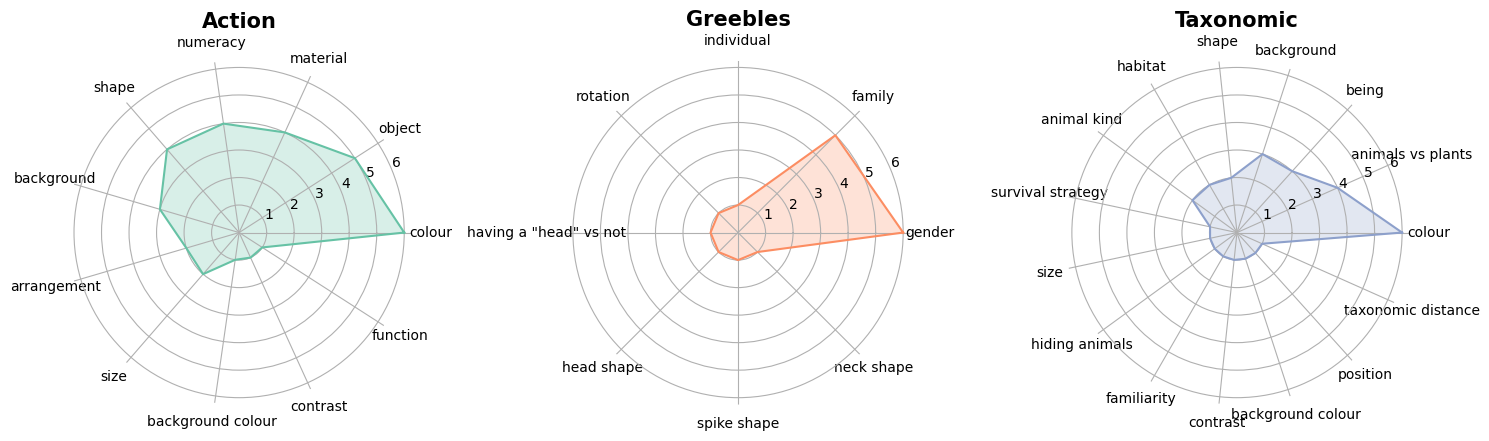

In [7]:
fig, axs = plt.subplots(figsize=(15, 5), nrows=1, ncols=3,subplot_kw=dict(polar=True))


data = {}
for set_name, ax in zip(set_names, axs):
    spoke_labels, data = make_data(set_name,data)
    N = len(spoke_labels)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    ax.set_thetagrids(np.degrees(angles), spoke_labels)
    ax.spines['polar'].set_visible(False)
    
    d = data[set_name]
    d.append(d[0]) # to get a circular plot
    angles.append(0)
    color = palette_imset[set_name]
    ax.plot(angles, d, color=color)
    ax.fill(angles, d, facecolor=color, alpha=0.25, label='_nolegend_')
    ax.set_title(set_name.capitalize(),fontsize=15,fontweight="bold")

plt.tight_layout()
fig.savefig("../plots/Criteria.png", dpi=300)
plt.show()

In [8]:
def make_data(set_name, data, participant):
    # get data in appropriate format
    set_data = data_df[data_df.set == set_name]
    if (participant != None):
        par_data = file_data[file_data.participant == participant].groupby(["set","criterion"]).count().reset_index()
        par_data = par_data[par_data.set == set_name]

    #set dependent changes
    if set_name == "greebles":
        set_data = set_data[set_data.criterion != "shape"] #this is already included in family, spike shape ect...
        set_data.criterion = [c if c != "object" else "individual" for c in set_data.criterion] #changing object to more appropriate individual for set

        #same changes in individual data
        par_data = par_data[par_data.criterion != "shape"] 
        par_data.criterion = [c if c != "object" else "individual" for c in par_data.criterion] 
        
    elif set_name == "taxonomic":
        set_data = set_data[set_data.criterion != "external similarities"] #deciding on similarities based on similarities...
        set_data = set_data[set_data.criterion != "looking similar"] #deciding on similarities based on similarities...
        set_data = set_data[set_data.criterion != "content connection"] #deciding on similarities based on connection also seems a bit vague
        set_data.criterion = [c if c != "object" else "being" for c in set_data.criterion] #changing object to more appropriate being for set
        set_data.criterion = [c if c != "arrangement" else "position" for c in set_data.criterion] #changing arrangement to more appropriate position for set

        #same changes in individual data
        par_data = par_data[par_data.criterion != "external similarities"] 
        par_data = par_data[par_data.criterion != "looking similar"] 
        par_data = par_data[par_data.criterion != "content connection"] 
        par_data.criterion = [c if c != "object" else "being" for c in par_data.criterion] 
        par_data.criterion = [c if c != "arrangement" else "position" for c in par_data.criterion]
    
    elif set_name == "action":
        set_data = set_data[set_data.criterion != "content connection"] #deciding on similarities based on connection...

        #same changes in individual data
        par_data = par_data[par_data.criterion != "content connection"] 
    
    criteria = set_data.criterion.to_list()
    #for individual participants criteria can only be either be used or not used
    par_criterion_list = par_data.criterion.to_list()
    criterion_list = set_data.criterion.to_list()
    data[set_name] = [1 if c in par_criterion_list else 0 for c in criterion_list]
    
    return criteria, data

Participant: O1


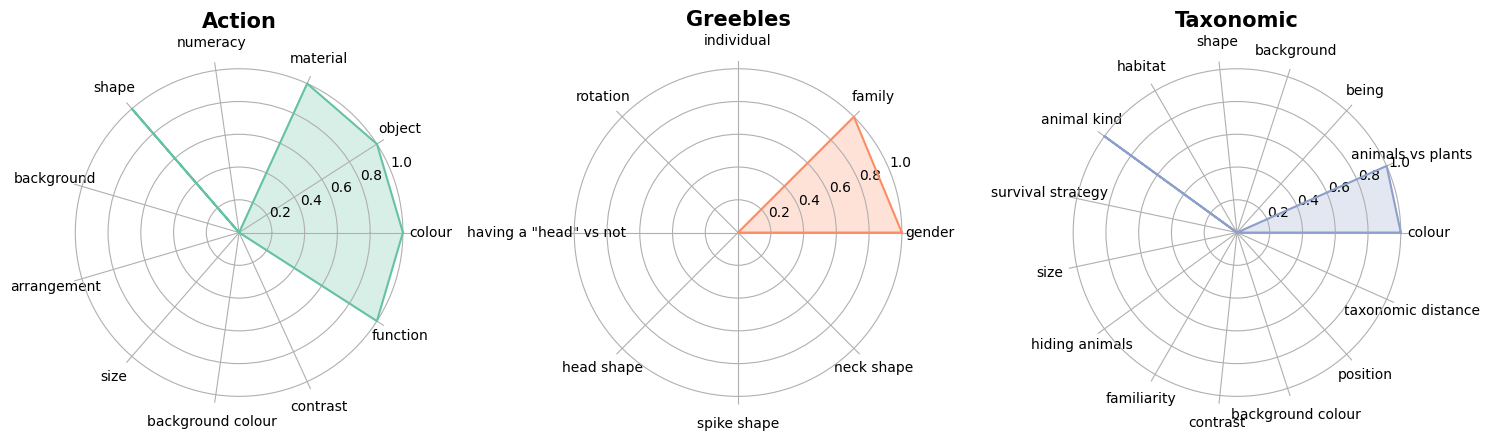

Participant: O2


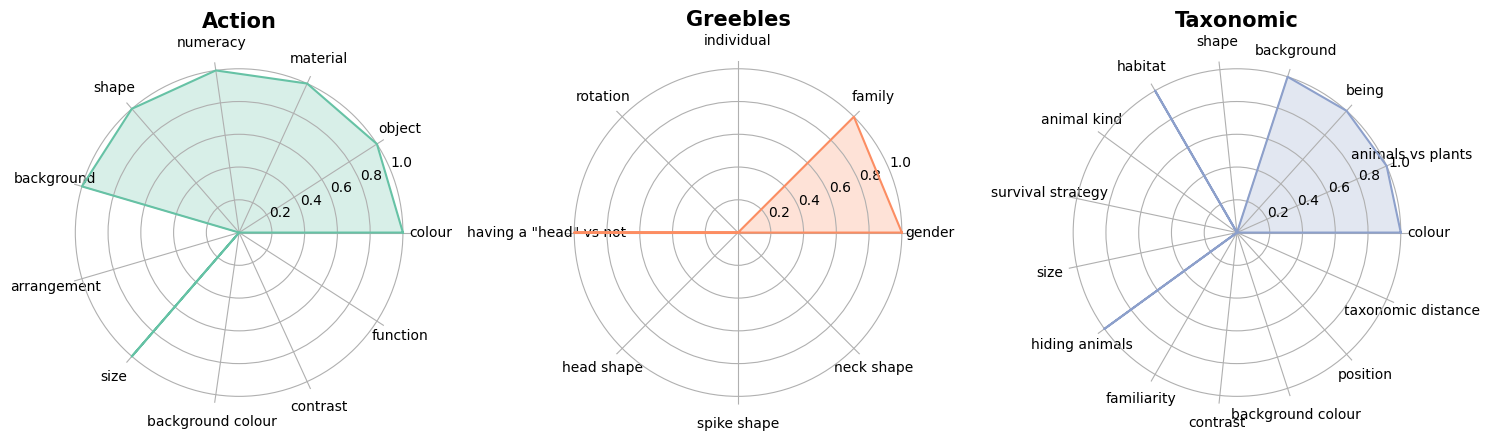

Participant: O3


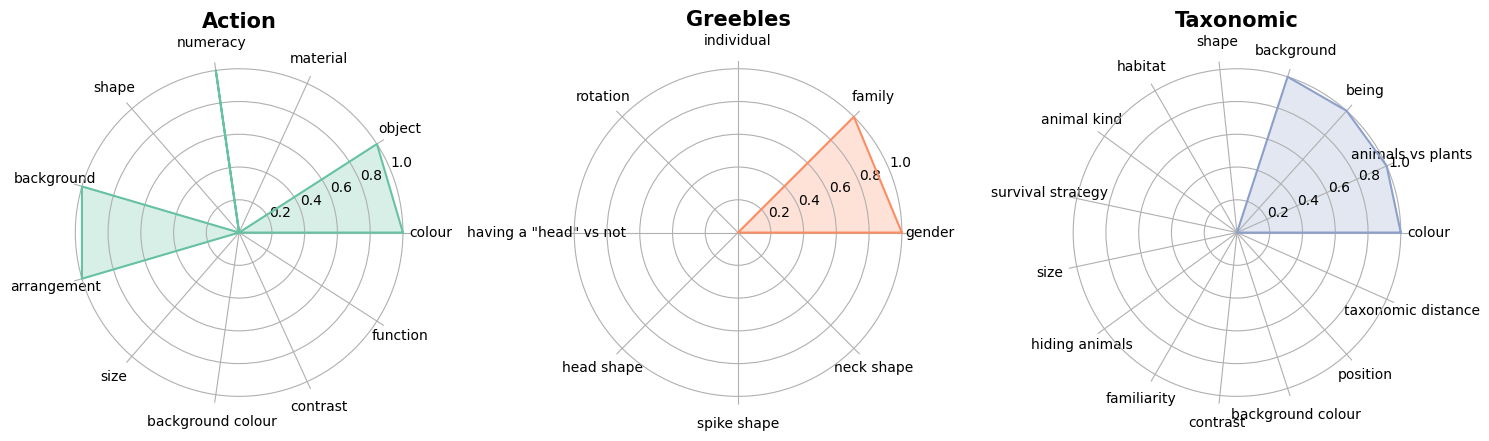

Participant: O4


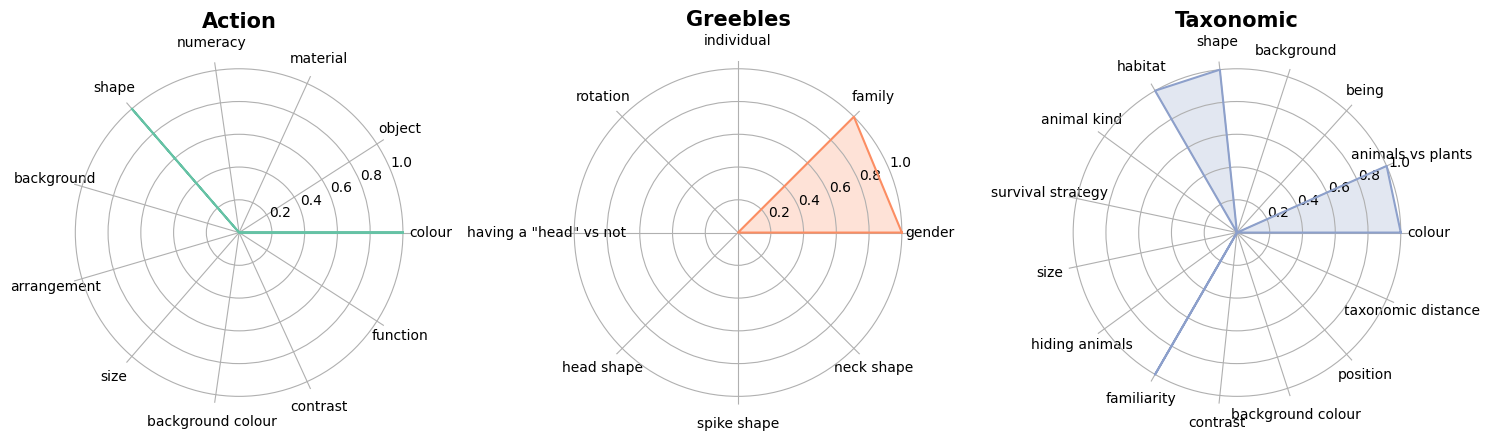

Participant: O5


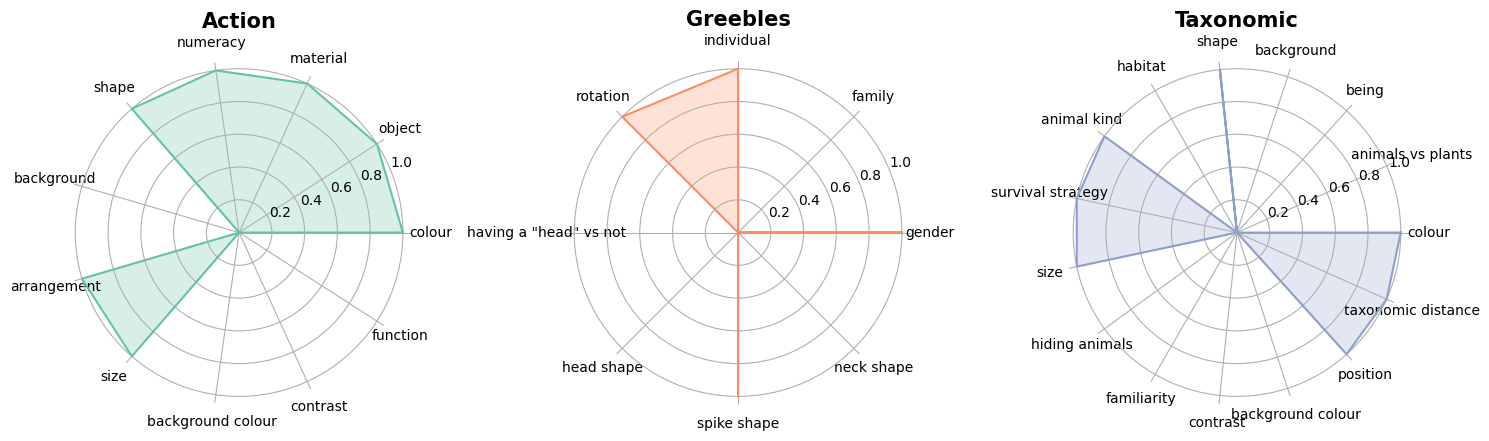

Participant: P2


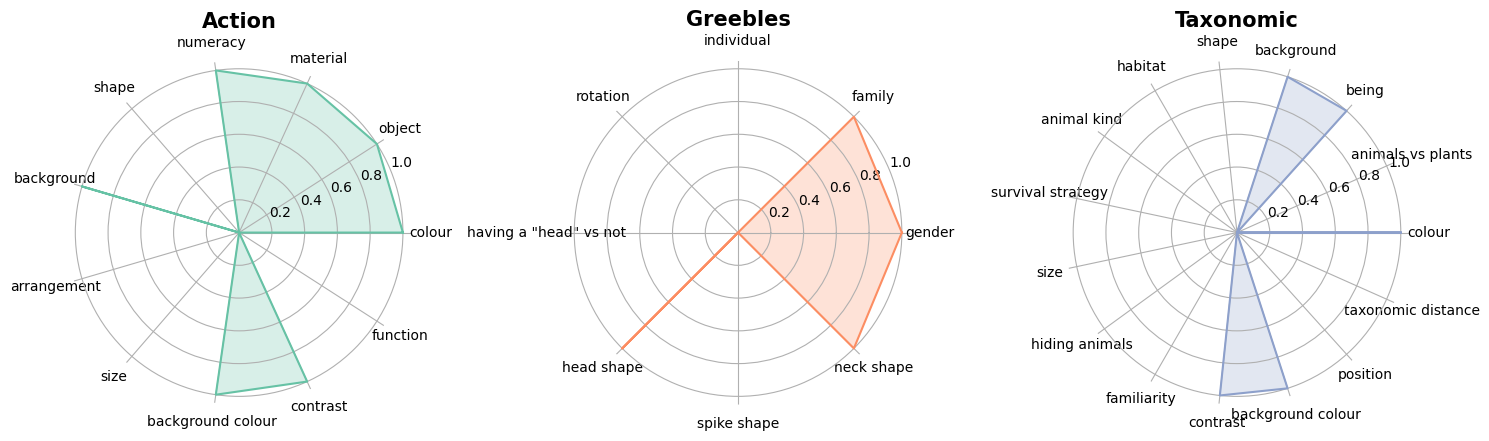

In [9]:
for p in np.unique(file_data.participant):
    fig, axs = plt.subplots(figsize=(15, 5), nrows=1, ncols=3,subplot_kw=dict(polar=True))
    
    
    data = {}
    for set_name, ax in zip(set_names, axs):
        spoke_labels, data = make_data(set_name,data,p)
        N = len(spoke_labels)
        angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
        ax.set_thetagrids(np.degrees(angles), spoke_labels)
        ax.spines['polar'].set_visible(False)
        
        d = data[set_name]
        d.append(d[0]) # to get a circular plot
        angles.append(0)
        color = palette_imset[set_name]
        ax.plot(angles, d, color=color)
        ax.fill(angles, d, facecolor=color, alpha=0.25, label='_nolegend_')
        ax.set_title(set_name.capitalize(),fontsize=15,fontweight="bold")
    
    plt.tight_layout()
    print("Participant: "+p)
    plt.show()